# 07: Is the Model Built Right?

## The question this notebook asks

The project's headline is that the car counts for about 2.8 times what the driver counts for. That
number comes from one particular model. This notebook asks whether that model was built correctly,
and whether a different one would have given a different answer.

**How the model works.** Every driver in every qualifying session gets one number: how far off the
fastest lap of that session they were, as a percentage. The model explains that gap as a sum of
pieces, one each for the driver, the car they were in that year and the season, plus whatever is left
over as unexplained. In code:
`(1|drv) + (1|team_season) + (1|season)`.

Notebook 02 settled the scale the gaps are measured on and the model family. It never asked whether
that list of pieces was the right list. Two later results suggest it was not.

**Each car gets a new number every season, and each driver gets one number for eight years.** Red
Bull's 2018 car and Red Bull's 2023 car are two different cars, so treating them separately is right.
But Verstappen gets a single number covering 2018 to 2025, as though he drove exactly as well every
year.

Nothing justified that difference, and it pushes one way. If a driver had a better season one year
than another, the model has nowhere to put it. It goes into the unexplained leftover or into the car's
number. Either way the driver's share comes out too small.

That also limited the year by year analysis in notebook 03. Only the car side could move there,
because the driver side is fixed by construction. So when the balance between car and driver appeared
to shift across seasons, there was no way to tell whether cars were converging or drivers were
spreading apart.

**There is no term for the circuit.** Over half the variation in qualifying gaps is currently unexplained, and
how well a car performs depends on where it is racing. A low-drag car is quick at Monza and slow at
Monaco. The circuit is in the data and the model has never used it.

This notebook tests both of those, and one more thing: whether taking each driver's **fastest** lap
rewards the drivers who ran the most laps.

**One note on the scale.** The model is fitted on the *square root* of that percentage gap, which
pulls in a long tail of ruined laps. Every share below is therefore a share of variance on that
square-root scale, and the 2.8 headline is a ratio of two such variances.

**Contents:**
1. The three candidate terms: circuit, driver-season and session.
2. Which version of the model the data prefers.
3. Does taking each driver's fastest lap reward the ones who ran more laps?
4. What this notebook changes.
5. Is 2.8 the data talking, or the model?

## Setup

Nothing new is downloaded. The table of driver-sessions notebook 02 saved has every column this
notebook needs.

That matters: these results are computed on exactly the same 3,008 driver-sessions the earlier numbers
came from. If an answer here differs from an answer there, the model is the cause, not the data.

In [57]:
!pip install -q bambi arviz

import glob

import numpy as np
import pandas as pd
import bambi as bmb
import arviz as az
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

model_data = pd.read_csv(glob.glob('/kaggle/input/**/model_data.csv', recursive=True)[0])
model_data['drv_season'] = model_data['drv'] + ' ' + model_data['season'].astype(str)
model_data['session'] = model_data['gp'] + ' ' + model_data['season'].astype(str)

# `gp` is the event name, not the venue. 2020 in particular ran two events at several
# tracks under different names, so a circuit term keyed on `gp` would split one track
# in two. Renames split one track the same way: the Mexico City and São Paulo events
# were called the Mexican and Brazilian Grands Prix earlier in this window, at the same
# two circuits. Only genuine duplicates are mapped; everything else keeps its name.
SHARED_VENUES = {
    'Styrian Grand Prix': 'Austrian Grand Prix',
    '70th Anniversary Grand Prix': 'British Grand Prix',
    'Emilia Romagna Grand Prix': 'Italian Grand Prix (Imola)',
    'San Marino Grand Prix': 'Italian Grand Prix (Imola)',
    'Mexican Grand Prix': 'Mexico City Grand Prix',
    'Brazilian Grand Prix': 'São Paulo Grand Prix',
}
model_data['circuit'] = model_data['gp'].replace(SHARED_VENUES)
collapsed = model_data['gp'].nunique() - model_data['circuit'].nunique()
print(f'event names: {model_data["gp"].nunique()}  ->  circuits: '
      f'{model_data["circuit"].nunique()} ({collapsed} collapsed)')
print('sessions:', model_data['session'].nunique())

print('rows:', len(model_data))
print('drivers:', model_data['drv'].nunique(),
      '| driver-seasons:', model_data['drv_season'].nunique(),
      '| team-seasons:', model_data['team_season'].nunique(),
      '| circuits:', model_data['circuit'].nunique())
print()
print('sessions per driver-season:')
print(model_data['drv_season'].value_counts().describe().round(1).to_string())

event names: 36  ->  circuits: 32 (4 collapsed)
sessions: 156
rows: 3008
drivers: 43 | driver-seasons: 171 | team-seasons: 81 | circuits: 32

sessions per driver-season:
count    171.0
mean      17.6
std        5.3
min        1.0
25%       15.0
50%       17.0
75%       22.0
max       24.0


## The three candidate terms

Three pieces could be added to the model. Here is what each one would mean.

**A circuit term, `(1|circuit)`, gives every track its own number.** It does not measure whether Monza
is faster than Monaco in absolute lap time; each driver's gap is already measured against the fastest
lap of that same session, so the raw speed of the track cancels out. It measures whether the field is
more spread out at some tracks than others. At one circuit the difference between the best car and the
worst is large; at another the whole grid is covered by a few tenths. That difference is real, and the
model has no place to record it, so it ends up in the unexplained leftover.

**A driver-season term, `(1|drv_season)`, gives every driver a separate number for each year.** On its
own it would be close to useless, because a driver in a given year sits in exactly one car. "Hamilton
in 2020" and "Mercedes in 2020" cover the same laps, so the model could not tell those two numbers
apart. The term only means something alongside the driver term that is already there:

- `(1|drv)` is a driver's **lasting ability**, one number for 2018 to 2025. One route to separating
  this from the car is the 21 drivers who changed constructor: when a driver moves teams, his pace
  travels with him and the car's does not. It is not the only route, and notebook 03 finds it is not
  even the main one. A driver who stays put is still compared against a run of different teammates,
  each of whom drove elsewhere, which is why Verstappen never left Red Bull and is still the most
  precisely estimated driver in the data.
- `(1|drv_season)` is how far that driver was **off his own usual level in one particular year**. What
  tells the model this is the teammate: two drivers in the same car that season, so any difference
  between them cannot be the car.

Splitting the driver in two asks how much of his contribution is permanent and how much is form that
comes and goes year to year.

**What the model is told before it sees any data.** A Bayesian model needs a starting assumption about
how large each piece could be. All three new terms get the same one as the existing driver and season
terms, `HalfNormal(0.3)`, rather than one chosen to suit them, so that assumption does not decide the
comparison. And if a term has nothing to explain, an assumption of this shape pulls it to zero by
itself rather than inventing work for it.

**A session term, `(1|session)`, gives every qualifying hour its own number.** Every driver's gap in a
session is measured against the same reference lap, so anything that moves that lap moves all twenty
gaps together: a damp track, a red flag, a benchmark set on a scruffy run. The model has nowhere to
put that, so it lands in the unexplained share. This is the term that turns out to matter most.

**Sampler settings.** These five fits draw 1,000 samples each rather than the 2,000 used in notebook
02. What is compared here is the share each piece takes, not the precise number for any one driver,
and the shares settle down long before the individual numbers do. All five use identical settings, so
no version is advantaged. Whichever version wins is refitted at full settings before anything
downstream depends on it.

**Why the convergence numbers below are computed by hand.**

This kind of model is not solved with a formula. It is fitted by a sampler that wanders through the
possible answers and records where it spends its time, four separate times from four different
starting points. Two standard checks say whether that worked.

**R-hat compares the four runs.** If all four settled in the same place it sits at about 1.00. Much
above that means they disagree and the answer should not be trusted.

**Effective sample size says how much independent information the sampler gathered.** Consecutive
steps of a wandering sampler resemble each other, so 1,000 steps are worth fewer than 1,000
independent draws. This number says how many.

Both are normally read off `az.summary`, which returns NaN for every parameter of these fits in the
version of the Kaggle environment used here. Convergence is the stated success criterion for this
project, so both are computed directly instead.

Neither calculation is invented. One difference is worth naming: the effective-sample-size routine
here normalises by the variance within each chain rather than by the pooled variance that includes
disagreement between chains, so where R-hat sits above 1.01 it reads a little optimistically. R-hat
here is the standard split version, which cuts each run in half and compares the variation inside the
halves against the variation between them. Effective sample size sums the correlation between steps
and stops where Geyer's rule says to stop, which is the usual method. **Neither is validated in this
notebook.** Notebook 03 checks the same two implementations against cases whose answer is known in
advance: independent draws return R-hat 1.000, four chains parked two standard deviations apart return
1.887, and a series with a known amount of correlation returns an effective size within about 3% of
theory. The code below is the same code.

In [58]:
import pymc as pm

BASE_PRIORS = {
    'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
    '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.5)),
    '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    'sigma': bmb.Prior('HalfNormal', sigma=0.5),
}
EXTRA_PRIORS = {
    '1|circuit': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|drv_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
    '1|session': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
}

SPECS = {
    'current': '1 + (1|drv) + (1|team_season) + (1|season)',
    'plus circuit': '1 + (1|drv) + (1|team_season) + (1|season) + (1|circuit)',
    'plus driver-season': '1 + (1|drv) + (1|drv_season) + (1|team_season) + (1|season)',
    'plus session': '1 + (1|drv) + (1|team_season) + (1|season) + (1|session)',
    'plus both': '1 + (1|drv) + (1|drv_season) + (1|team_season) + (1|season) + (1|circuit)',
}


def build_spec(name):
    terms = SPECS[name]
    priors = {**BASE_PRIORS, **{k: v for k, v in EXTRA_PRIORS.items() if k in terms}}
    return bmb.Model(f'sqrt_gap ~ {terms}', data=model_data, priors=priors)


def add_log_likelihood(model, idata):
    """LOO needs this group, and passing it through fit() does not produce it here.

    Never raises: losing a fit that took minutes to a failed extra is not worth it.
    Bambi's non-centred parameterisation trips the plain PyMC route, so try Bambi's
    own method first.
    """
    # hasattr is true for an empty group, and `groups` is a method in some arviz
    # versions and a property in others, so check the contents directly
    group = getattr(idata, 'log_likelihood', None)
    if group is not None and len(group.data_vars) > 0:
        return 'already present'
    try:
        model.compute_log_likelihood(idata)
        return 'bambi'
    except Exception as bambi_error:
        try:
            model.build()
            with model.backend.model:
                pm.compute_log_likelihood(idata)
            return 'pymc'
        except Exception as pymc_error:
            return (f'unavailable, bambi: {type(bambi_error).__name__}, '
                    f'pymc: {type(pymc_error).__name__}')


def split_rhat(draws):
    """Split R-hat: within-chain against between-chain variance, halves compared."""
    chains, length = draws.shape
    half = length // 2
    pieces = np.concatenate([draws[:, :half], draws[:, half:2 * half]])
    within = pieces.var(axis=1, ddof=1).mean()
    between = half * pieces.mean(axis=1).var(ddof=1)
    return np.sqrt(((half - 1) / half * within + between / half) / within)


def effective_size(draws):
    """ESS from the autocorrelation, truncated by Geyer's initial positive sequence."""
    chains, length = draws.shape
    centred = draws - draws.mean(axis=1, keepdims=True)
    padded = 2 ** int(np.ceil(np.log2(2 * length)))
    spectrum = np.fft.rfft(centred, n=padded, axis=1)
    autocovariance = np.fft.irfft(spectrum * np.conjugate(spectrum), n=padded,
                                  axis=1)[:, :length].real / length
    correlation = autocovariance.mean(axis=0)
    correlation = correlation / correlation[0]
    total = 0.0
    for lag in range(1, length - 1, 2):
        pair = correlation[lag] + correlation[lag + 1]
        if pair < 0:
            break
        total += pair
    return chains * length / (1 + 2 * total)


def report_convergence(label, idata):
    """arviz returns NaN for these fits in the current image, so compute it here.

    Covers the scalar parameters only (the intercept, the residual sd and the group sds),
    not the ~130 individual group-level effects, so 'worst R-hat' is worst among those.
    """
    scalars = [name for name in idata.posterior.data_vars
               if idata.posterior[name].dims == ('chain', 'draw')]
    rhats = {name: split_rhat(idata.posterior[name].values) for name in scalars}
    sizes = {name: effective_size(idata.posterior[name].values) for name in scalars}
    worst = max(rhats, key=rhats.get)
    print(f'{label:22s} divergences {int(idata.sample_stats["diverging"].sum()):3d}  '
          f'worst R-hat {rhats[worst]:.4f} ({worst})  '
          f'lowest ESS {min(sizes.values()):,.0f}')


def fit_spec(name):
    model = build_spec(name)
    idata = model.fit(draws=1000, tune=1000, chains=4, random_seed=0, target_accept=0.99)
    print(f'{name:20s} log likelihood via {add_log_likelihood(model, idata)}')
    report_convergence(name, idata)
    return idata


fits = {}

In [59]:
fits['current'] = fit_spec('current')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 70 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


current              log likelihood via bambi
current                divergences   0  worst R-hat 1.0151 (1|season_sigma)  lowest ESS 650


In [60]:
fits['plus circuit'] = fit_spec('plus circuit')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset, 1|circuit_sigma, 1|circuit_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 72 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


plus circuit         log likelihood via bambi
plus circuit           divergences   0  worst R-hat 1.0103 (1|season_sigma)  lowest ESS 497


In [61]:
fits['plus driver-season'] = fit_spec('plus driver-season')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|drv_season_sigma, 1|drv_season_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 52 seconds.
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


plus driver-season   log likelihood via bambi
plus driver-season     divergences   0  worst R-hat 1.0049 (1|season_sigma)  lowest ESS 446


In [62]:
fits['plus session'] = fit_spec('plus session')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset, 1|session_sigma, 1|session_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 76 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


plus session         log likelihood via bambi
plus session           divergences   0  worst R-hat 1.0213 (1|season_sigma)  lowest ESS 360


In [63]:
fits['plus both'] = fit_spec('plus both')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|drv_season_sigma, 1|drv_season_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset, 1|circuit_sigma, 1|circuit_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 62 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


plus both            log likelihood via bambi
plus both              divergences   0  worst R-hat 1.0138 (1|season_sigma)  lowest ESS 369


## Which version of the model the data prefers

Five versions have been fitted. Something has to rank them.

**LOO is the standard way to do that.** Short for leave-one-out. It estimates how well each version
would predict a driver-session it had never seen, by setting observations aside one at a time and
checking the prediction against what happened. Higher is better.

All five versions predict the same quantity on the same scale, so their scores can be compared
directly. That was not true in notebook 02, where one model predicted a transformed lap gap and
another the raw one. Scores from those two cannot be compared without a conversion factor, which is
why that comparison was ruled out there.

The number to read is `elpd_diff`, the gap in score between a version and the best one, against the
standard error of that gap. If the gap is smaller than about twice its own standard error, the two
versions are not distinguishable and there is no case for switching.

Both diagnostics below are computed by hand rather than through `az.summary`, which returns NaN for
every parameter of these fits in the current Kaggle image. LOO needs no such workaround: `fit_spec`
records the log-likelihood at fit time, which the `log likelihood via bambi` line in each fit above
confirms, so the check below verifies that the group is present on all five.

In [64]:
for name, idata in fits.items():
    print(f'{name:20s} log likelihood via {add_log_likelihood(build_spec(name), idata)}')

current              log likelihood via already present
plus circuit         log likelihood via already present
plus driver-season   log likelihood via already present
plus session         log likelihood via already present
plus both            log likelihood via already present


In [65]:
for name, idata in fits.items():
    report_convergence(name, idata)
print()

for name, idata in fits.items():
    try:
        az.loo(idata)
        print(f'{name:20s} loo ok')
    except Exception as error:
        print(f'{name:20s} loo failed: {type(error).__name__}: {error}')
print()

try:
    comparison = az.compare(fits)
    display(comparison.round(2))
except Exception as error:
    comparison = None
    print('LOO comparison unavailable:', error)
    print('The variance shares below still answer whether each term is doing any work.')

current                divergences   0  worst R-hat 1.0151 (1|season_sigma)  lowest ESS 650
plus circuit           divergences   0  worst R-hat 1.0103 (1|season_sigma)  lowest ESS 497
plus driver-season     divergences   0  worst R-hat 1.0049 (1|season_sigma)  lowest ESS 446
plus session           divergences   0  worst R-hat 1.0213 (1|season_sigma)  lowest ESS 360
plus both              divergences   0  worst R-hat 1.0138 (1|season_sigma)  lowest ESS 369

current              loo ok
plus circuit         loo ok
plus driver-season   loo ok


/usr/local/lib/python3.12/dist-packages/arviz_stats/loo/loo_helper.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


plus session         loo ok
plus both            loo ok



/usr/local/lib/python3.12/dist-packages/arviz_stats/loo/loo_helper.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
plus session,0,0.0,0.0,NaN,,2 k̂ > 0.70,240.9,-300.0,59.0,0.91
plus circuit,1,-320.0,33.0,1.0,,,133.4,-600.0,54.0,0.00
plus both,2,-320.0,33.0,1.0,,,138.8,-600.0,54.0,0.00
current,3,-390.0,38.0,1.0,,,106.1,-700.0,54.0,0.00
plus driver-season,4,-400.0,38.0,1.0,,,111.0,-700.0,55.0,0.09


In [66]:
group_sigmas = {
    'driver': '1|drv_sigma',
    'driver-season': '1|drv_season_sigma',
    'car': '1|team_season_sigma',
    'circuit': '1|circuit_sigma',
    'session': '1|session_sigma',
    'season': '1|season_sigma',
    'unexplained': 'sigma',
}


def variance_shares(idata):
    posterior = idata.posterior
    present = {label: posterior[name].values.flatten() ** 2
               for label, name in group_sigmas.items() if name in posterior}
    total = sum(present.values())
    return pd.DataFrame({label: values / total for label, values in present.items()})


rows = []
for name, idata in fits.items():
    shares = variance_shares(idata)
    driver_total = shares['driver'] + shares.get('driver-season', 0)
    entry = {'spec': name}
    for column in shares:
        entry[column] = shares[column].median() * 100
    entry['driver total'] = driver_total.median() * 100
    entry['car : driver'] = (shares['car'] / driver_total).median()
    rows.append(entry)

pd.DataFrame(rows).set_index('spec').round(2)

,driver,car,season,unexplained,driver total,car : driver,circuit,driver-season,session
spec,,,,,,,,,
current,11.15,31.28,3.19,52.37,11.15,2.80,NaN,NaN,NaN
plus circuit,11.23,31.47,2.54,48.49,11.23,2.81,4.15,NaN,NaN
plus driver-season,10.99,31.01,3.13,52.54,11.28,2.76,NaN,0.15,NaN
plus session,11.05,31.07,2.12,36.96,11.05,2.81,NaN,NaN,16.49
plus both,10.97,31.18,2.68,48.39,11.27,2.77,4.18,0.20,NaN


### What each added term does to the answer

| spec | driver | driver-season | car | circuit | season | session | unexplained | car : driver |
|---|---|---|---|---|---|---|---|---|
| current | 11.15 | | 31.28 | | 3.19 | | 52.37 | **2.80** |
| plus circuit | 11.23 | | 31.47 | **4.15** | 2.54 | | 48.49 | 2.81 |
| plus driver-season | 10.99 | **0.15** | 31.01 | | 3.13 | | 52.54 | 2.76 |
| **plus session** | 11.05 | | 31.07 | | 2.12 | **16.49** | **36.96** | **2.81** |
| plus both | 10.97 | 0.20 | 31.18 | 4.18 | 2.68 | | 48.39 | 2.77 |

**How to read the table.** Each row is one version of the model. The numbers are percentages of all
the variation in qualifying pace, split by what the model thinks caused it. A blank means that version
does not contain that term; every version contains a season term. The last column is the car's share
divided by the driver's, where "the driver's" means driver plus driver-season on the two rows that
carry both. It is the median of that ratio across draws rather than the ratio of the two medians, so
it will not reproduce exactly from the columns beside it. The same applies to the driver total quoted
further down: it is the median of the per-draw sum, not the sum of the two medians in the table,
which is why 10.99 and 0.15 do not add to it.

**The biggest finding here is the session term, and it is about neither drivers nor cars.** Giving
each qualifying session its own number takes **16.5%** of the total and cuts the unexplained share
from 52.4% to **37.0%**. About a third of what this project has been calling unexplained is not noise.
It is something all twenty drivers in a session share.

The way the target is built predicts this. Every gap in a session is measured against one lap, the
fastest lap of Q1. If that lap happened to be unusually good, all twenty gaps look worse together; if
the track was still green when it was set, they all look better together. The session term catches
that shared movement. It leaves the car-to-driver ratio at 2.81, so it changes where the variation is
booked, not what the project concludes.

**The circuit term is real, and it is worth about 4% of the total.** `gp` is an event name, not a
venue: the Red Bull Ring, Silverstone, Mexico City and Interlagos each appear under two names, so a
term keyed on `gp` splits four circuits in two. Mapping them gives 32 circuits and a share of 4.15%,
against 4.24% with no map and 3.98% with the map half done. **That it moves in both directions is the
useful part**: on about 94 rows per circuit, 4% is the right order rather than a precise figure.

The unexplained share falls from 52.37% to 48.49% when the circuit term is added, a drop of 3.88 points
against the 4.15% the new term takes. The two roughly matching is the point: the circuit term picks up
variation that was there and unaccounted for, rather than taking work away from a term that already
existed.

**The driver-season term is not real.** It takes **0.15%** of the total, which is nothing. Once you
know a driver's lasting ability and which car he was in that year, knowing *which* year it was tells
you almost nothing more about his pace.

**That settles the concern that prompted this notebook, and it settles it against me.** I argued that
freezing a driver's number for eight years while letting cars change annually would push real
variation into the unexplained pile and understate the driver. It does not, because there is almost no
year-to-year variation to push anywhere. Across 2018 to 2025, a driver's qualifying pace relative to
his machinery is close to a fixed property.

Three things follow:

1. **The career-level driver ratings in notebook 03 are defensible.** Averaging a driver over eight
   seasons is not hiding a moving target underneath.
2. **The per-season analysis in notebook 03 was not crippled by its driver side being constant.** The
   driver side had almost nothing to contribute, so anything that moves in a per-season ratio is the
   car side moving. That is a statement about how the model is built and nothing more. Notebook 03
   went on to **withdraw** the per-season trend itself, for reasons unrelated to this term.
3. **The headline does not move.** The ratio runs 2.80, 2.81, 2.76, 2.81 and 2.77 across the five
   specifications, a spread of 0.05 on a value of about 2.8. Notebook 03's interval for this number,
   [1.6, 5.3], is 3.7 wide, so which specification you pick moves the answer by less than a fiftieth
   of what the data itself leaves open.

**The sampler behaved, with one reservation.** No fit produced a single divergence, which is the
sampler's own alarm for a region of the answer space it could not explore properly. Worst R-hat runs
from 1.0049 to 1.0213 and lowest effective sample size from 360 to 650, against notebook 02's primary
model which used twice as many draws. Four of the five sit above the conventional 1.01 threshold,
including `current`, the primary specification, so the individual driver and car numbers here are
known less precisely than in the primary model.

The worst parameter is `1|season_sigma` in every fit, which is where it should be. There are only
eight seasons in the data, so the size of the season piece has the least evidence behind it. It
matters less here than it would elsewhere, because the conclusion that matters, the ratio, rests on
shares that move little: the car share spans 0.46 percentage points across the five fits and the
driver total 0.23. The unexplained share is a different story, spanning 15.6 points, because the
session term absorbs so much of it. Those fits also share a seed and the same 3,008 rows, so this is
not five independent estimates.

The figure below decomposes `plus session`, the specification LOO ranks first, not the one this
notebook ships. That is deliberate: it shows what the session term does to the split.

**The LOO comparison did run, and it prefers a model this notebook does not ship.** `plus session`
ranks first and takes 0.91 of the weight. The current specification comes fourth, 390 elpd behind
against a standard error of 38, about ten standard errors apart and decisive by the rule set out
above. Two things to hold alongside that: arviz flags two observations with high Pareto k for the
winning model, and LOO rewards predicting individual laps, which is not the question this project
asks. So the session term is left out of the shipped model because it answers a different question,
not because the data cannot tell the two apart. The data can, and saying so is the honest version.

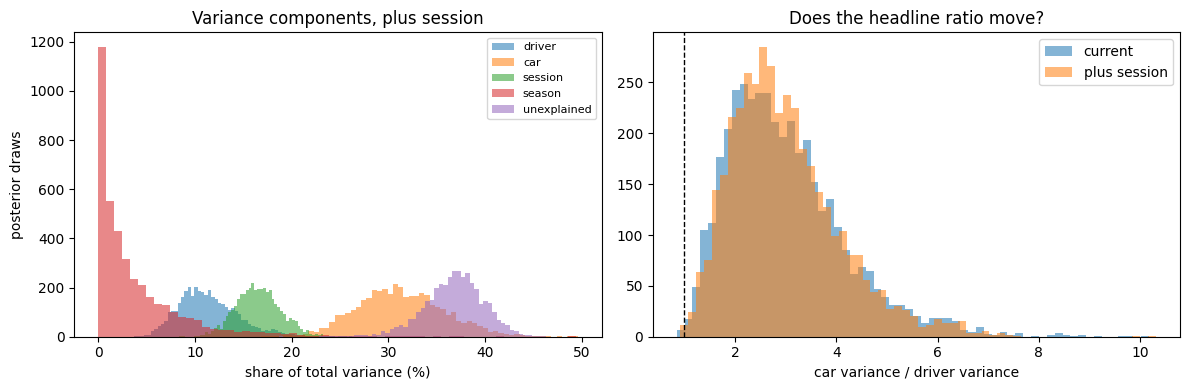

In [67]:
# without LOO, fall back to the fullest specification for the illustration
best = comparison.index[0] if comparison is not None else 'plus both'
shares = variance_shares(fits[best])

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for column in shares.columns:
    axes[0].hist(shares[column] * 100, bins=60, alpha=0.55, label=column)
axes[0].set_xlabel('share of total variance (%)')
axes[0].set_ylabel('posterior draws')
axes[0].set_title(f'Variance components, {best}')
axes[0].legend(fontsize=8)

for label in ['current', best]:
    series = variance_shares(fits[label])
    total = series['driver'] + series.get('driver-season', 0)
    axes[1].hist(series['car'] / total, bins=60, alpha=0.55, label=label)
axes[1].axvline(1, color='k', ls='--', lw=1)
axes[1].set_xlabel('car variance / driver variance')
axes[1].set_title('Does the headline ratio move?')
axes[1].legend()

plt.tight_layout()
plt.show()

## Does taking each driver's fastest lap reward the ones who ran more laps?

A driver's pace in this project is his quickest valid lap in Q1. That creates a possible problem with
nothing to do with driving.

**More attempts means more chances at a good one.** A driver who completed four flying laps had four
attempts; a driver who completed two had two. Tyre temperature, traffic and a tidy exit out of the
last corner vary from lap to lap, so the best of four beats the best of two on average even if the two
drivers are equally quick. The model would read that difference as speed.

**And run count is not random.** A team in trouble sends the car back out. A team already safely
through to Q2 does not. Notebook 01 saw a version of this: the driver-sessions removed by the 107%
rule had a median of 2 valid laps against 3 for the rows that were kept.

**The prediction, written down before the test was run.** If the quicker teams run fewer laps, they
get fewer attempts at a good minimum, their measured gap looks worse than their true pace, and the
measured difference between the fastest and slowest cars ends up smaller than it really is. Hold run
count still and that difference should get wider.

In [68]:
lap_counts = model_data['n_valid_laps'].value_counts().sort_index()
print('driver-sessions by number of valid Q1 laps:')
print(lap_counts.to_string())
print()

pace_by_laps = model_data.groupby('n_valid_laps')['gap_to_fastest'].agg(['size', 'median'])
print('median gap by run count:')
print(pace_by_laps.round(3).to_string())
print()

MODE_LAPS = int(lap_counts.idxmax())
same_runs = model_data[model_data['n_valid_laps'] == MODE_LAPS]
print(f'holding run count at {MODE_LAPS}: {len(same_runs)} rows, '
      f'{same_runs["drv"].nunique()} drivers, {same_runs["team_season"].nunique()} team-seasons')
print('drivers who still changed constructor:',
      int((same_runs.groupby('drv')['team'].nunique() > 1).sum()))

driver-sessions by number of valid Q1 laps:
n_valid_laps
1     339
2     845
3     532
4     437
5     369
6     238
7     102
8      94
9      37
10      7
11      8

median gap by run count:
              size  median
n_valid_laps              
1              339   0.769
2              845   0.912
3              532   0.977
4              437   0.975
5              369   0.932
6              238   1.133
7              102   1.005
8               94   1.412
9               37   1.520
10               7   1.301
11               8   0.868

holding run count at 2: 845 rows, 41 drivers, 81 team-seasons
drivers who still changed constructor: 19


**The prediction was wrong, and the table above shows why.** Median gap by run count runs 0.77, 0.91,
0.98, 0.98, 0.93, 1.13, 1.01, 1.41, 1.52 for the first nine counts, then 1.30 and 0.87 for the last
two, which rest on a handful of sessions each. More laps go with a **worse** gap, not a better one,
and the drivers who set just one lap are the quickest of the lot.

The mechanical advantage of extra attempts is real. It is swamped by the reason drivers take those
attempts. A car quick enough to be safe can bank one lap in Q1 and stop; a car on the bubble has to go
out again. So run count is mostly a symptom of pace rather than a cause of it.

That has a direct consequence. **Adjusting for run count would be wrong.** Subtracting off whatever
run count predicts would take genuine pace with it, because most of what run count measures is pace.

The test below does something different. It keeps only the driver-sessions with the same number of
valid laps and refits the model on those, so the mechanical effect is gone by construction and nothing
has been adjusted away.

In [69]:
subset_model = bmb.Model(f'sqrt_gap ~ {SPECS["current"]}', data=same_runs, priors=BASE_PRIORS)
subset_idata = subset_model.fit(draws=1000, tune=1000, chains=4, random_seed=0, target_accept=0.99)

report_convergence(f'{MODE_LAPS} laps only', subset_idata)
print()

subset_shares = variance_shares(subset_idata)
full_shares = variance_shares(fits['current'])

sensitivity = pd.DataFrame([
    {'fit': 'all run counts', 'rows': len(model_data),
     **{c: full_shares[c].median() * 100 for c in full_shares},
     'car : driver': (full_shares['car'] / full_shares['driver']).median()},
    {'fit': f'{MODE_LAPS} laps only', 'rows': len(same_runs),
     **{c: subset_shares[c].median() * 100 for c in subset_shares},
     'car : driver': (subset_shares['car'] / subset_shares['driver']).median()},
]).set_index('fit')

sensitivity.round(2)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 31 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


2 laps only            divergences   0  worst R-hat 1.0078 (1|season_sigma)  lowest ESS 704



,rows,driver,car,season,unexplained,car : driver
fit,,,,,,
all run counts,3008,11.15,31.28,3.19,52.37,2.80
2 laps only,845,14.05,27.29,6.98,48.99,1.95


### Why holding run count fixed cannot answer the question

**The fit itself was fine.** R-hat **1.0078**, lowest effective sample size **704**, no divergences.
An earlier version of this notebook reported an R-hat of 31 million and concluded the sampler had
failed. That number came from a broken `az.summary` call, not from the fit, and the conclusion drawn
from it was wrong. Throwing the result away was still right, for a different reason.

**A sampler that worked is not the same thing as a question the data can answer.** Holding run count
at 2 leaves 845 driver-sessions spread across 81 team-seasons, about **ten** apiece against
**thirty-seven** in the full data.

Ten sessions is not much to judge a car on. When the evidence for a team is thin, this kind of model
pulls that team's number toward the middle of the grid rather than trusting a small sample. Pull all
81 teams toward the middle and the measured spread between the best and worst cars shrinks. So the car
share falling from 31.28 to 27.29 has an explanation with nothing to do with run count. The driver
share moves further in the same subset, rising 11.15 to 14.05, and it accounts for more of the drop
from 2.80 to 1.95 than the car side does.

**The subset is also not the same population.** Its unexplained share is 48.99 against 52.37, and its
season share 6.98 against 3.19. Sessions where a driver set exactly two valid laps differ from the
rest in more ways than the one being tested.

So the 1.95 that comes out is a genuine summary of a model fitted to data too thin to be compared
against the full one. Reporting it as a finding would have been wrong either way. What makes this a
by-product of the test rather than a result is how the test was designed, not how the sampler behaved.

**The concern still deserves an answer, so the test changes shape.** Instead of holding run count
fixed on a subset too small to support the model, the full data is refitted with run count included as
a predictor, letting the model subtract off whatever run count explains. That is the adjustment argued
against above, which makes it a **bound rather than a correction**: it removes the mechanical effect
and some genuine pace along with it. If even that does not move the car-to-driver ratio, then neither
channel matters for the split between driver and car.

In [70]:
# a per-lap effect above 0.1 would be implausible on a response that spans roughly 0 to 2
covariate_priors = {**BASE_PRIORS, 'n_valid_laps': bmb.Prior('Normal', mu=0, sigma=0.1)}

covariate_model = bmb.Model(
    f'sqrt_gap ~ 1 + n_valid_laps + (1|drv) + (1|team_season) + (1|season)',
    data=model_data, priors=covariate_priors)
covariate_idata = covariate_model.fit(draws=1000, tune=1000, chains=4,
                                      random_seed=0, target_accept=0.99)
report_convergence('run count controlled', covariate_idata)

slope = covariate_idata.posterior['n_valid_laps'].values.flatten()
print(f'\nrun-count slope: {np.median(slope):+.4f} per lap '
      f'[{np.percentile(slope, 5.5):+.4f}, {np.percentile(slope, 94.5):+.4f}]')
print()

covariate_shares = variance_shares(covariate_idata)
baseline_shares = variance_shares(fits['current'])

run_count_check = pd.DataFrame([
    {'fit': 'current', **{c: baseline_shares[c].median() * 100 for c in baseline_shares},
     'car : driver': (baseline_shares['car'] / baseline_shares['driver']).median()},
    {'fit': 'run count controlled',
     **{c: covariate_shares[c].median() * 100 for c in covariate_shares},
     'car : driver': (covariate_shares['car'] / covariate_shares['driver']).median()},
]).set_index('fit')

run_count_check.round(2)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, n_valid_laps, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 69 seconds.


run count controlled   divergences   0  worst R-hat 1.0044 (1|season_sigma)  lowest ESS 518

run-count slope: +0.0164 per lap [+0.0118, +0.0210]



,driver,car,season,unexplained,car : driver
fit,,,,,
current,11.15,31.28,3.19,52.37,2.80
run count controlled,10.83,31.70,3.11,52.56,2.92


### What run count actually does to the answer

| | driver | car | unexplained | car : driver |
|---|---|---|---|---|
| current | 11.15 | 31.28 | 52.37 | **2.80** |
| run count controlled | 10.83 | 31.70 | 52.56 | **2.92** |

**Each extra lap goes with a slightly worse gap, not a better one.** The run-count slope is
**+0.0164 per lap** [+0.0118, +0.0210], clear of zero and **positive**. That confirms what the
descriptive table showed. If the best-of-N advantage were the dominant force, the slope would point
the other way.

**Subtracting run count off moves the car-to-driver ratio from 2.80 to 2.92, a rise of 4%.**

**The size is what settles it.** Notebook 03's interval for this ratio, [1.6, 5.3], is 3.7 wide, so a
shift of 0.12 is a thirtieth of what the data already leaves open. The estimate is a **bound rather
than a correction**, because the adjustment also strips out genuine pace, so the true effect is
smaller than 0.12. The concern was worth testing and is now closed.

## What this notebook changes

**Nothing about the headline, and that is the result.** Three plausible missing terms and one possible
bias in the target were tested against the model as it stands:

| checked | verdict |
|---|---|
| Driver skill frozen across eight seasons | Harmless. Year-to-year variation is 0.15% of the total |
| No circuit term | Real, 4.15% of the total, cuts unexplained from 52.4% to 48.5% |
| No session term | **Real and large**, 16.5% of the total, cuts unexplained from 52.4% to 37.0% |
| Fastest-lap target rewards more attempts | **Not found**: more laps go with a worse gap, and controlling for run count moves the ratio 4% the other way |

The car-to-driver ratio holds between 2.76 and 2.92 across the versions tried **here**, all of which
use Q1 laps with the 107% filter applied. That is a narrower claim than it looks. Notebook 06 refits
the same question on Q2 and Q3, and on other data filters, and spans **1.9x to 4.7x**.

So the number to quote is not a tight range around 2.8. It is [1.57, 5.27], the range of values the
data supports.

**The primary model stays as it is.** Adding the circuit term would give a better account of where the
variation comes from without changing anything the project concludes, and adopting it would mean
refitting every downstream result to move the headline by 0.01.

One number should be amended. Notebook 03 states that 52.6% of the variation is unexplained. About 4
points of that is circuit-driven, and the session term accounts for a further 15, taking unexplained
to 37.0% in the fit that includes it. The two are never fitted together here, so the combined figure
is not computed, but "52.6% unexplained" overstates what is genuinely unaccounted for.

## Is 2.8 the data talking, or the model?

Everything so far shows the ratio is **stable**. It holds across five versions of the model, a
run-count control, three parts of qualifying and several data filters.

Stability is not correctness. A number can be stable because the data pins it down, or stable because
something built into the model pins it down regardless of what the data says. Those two look identical
from the outside.

There is nothing here to score against. The podium classifier in notebook 04 can be checked against
who finished on the podium; the answer exists and is public. Nobody knows the true split between
driver and car, so no equivalent check exists. Two indirect tests stand in for the direct one that is
missing.

**The first test: the model's starting assumptions are not symmetric, and the asymmetry points at the
answer.** Before it sees a single lap, the model is told how large each piece could be. The driver
term `(1|drv)` is given `HalfNormal(0.3)` and the car term `(1|team_season)` is given
`HalfNormal(0.5)`, so the car was allowed to be the bigger of the two from the outset, which is what
the model went on to report. With 81 team-seasons at roughly 37 sessions each the data should easily
overwhelm a starting assumption that mild, but "should" is not a demonstration.

**The second test: give the model a question whose answer is already known.** Invent a dataset in
which the car matters exactly as much as the driver, keeping everything real about the sport: the same
43 drivers, the same 81 team-seasons, the same record of who drove what and how often. Only the lap
times are made up. Then fit the model to that invented data and see what it hands back.

That gives three outcomes worth caring about. If a true ratio of 1 comes back as 2.8, the method is
biased. If a true 1 and a true 5 both come back near 2.8, this dataset cannot tell them apart and the
headline is coming from the starting assumption rather than from Formula 1. If the method returns
roughly what was put in, the headline is earned.

### Does the answer change when the starting assumptions change?

Four settings are tried for the two numbers that tell the model in advance how large the driver piece
and the car piece could be, with everything else held as it is. One setting matches the model as
fitted; the other three remove the asymmetry by giving driver and car the same allowance, at three
different widths.

If the answer moves when those settings move, the assumption is deciding it rather than the data.

In [71]:
PRIOR_SETTINGS = {
    'as fitted (0.3 / 0.5)': (0.3, 0.5),
    'matched tight (0.3)': (0.3, 0.3),
    'matched wide (0.5)': (0.5, 0.5),
    'matched very wide (1.0)': (1.0, 1.0),
}


def fit_with_scales(driver_scale, car_scale, data=None):
    priors = {
        'Intercept': bmb.Prior('Normal', mu=1, sigma=0.5),
        '1|drv': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=driver_scale)),
        '1|team_season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=car_scale)),
        '1|season': bmb.Prior('Normal', mu=0, sigma=bmb.Prior('HalfNormal', sigma=0.3)),
        'sigma': bmb.Prior('HalfNormal', sigma=0.5),
    }
    model = bmb.Model('sqrt_gap ~ 1 + (1|drv) + (1|team_season) + (1|season)',
                      data=model_data if data is None else data, priors=priors)
    # progressbar off: its widget stream stalls Kaggle's batch runner on long cells
    return model.fit(draws=1000, tune=1000, chains=4, random_seed=0, target_accept=0.99,
                     progressbar=False)


def ratio_summary(idata):
    shares = variance_shares(idata)
    ratio = shares['car'] / shares['driver']
    return {'car : driver': ratio.median(),
            'lower_89': ratio.quantile(0.055),
            'upper_89': ratio.quantile(0.945),
            'driver %': shares['driver'].median() * 100,
            'car %': shares['car'].median() * 100}


prior_rows = []
for label, (driver_scale, car_scale) in PRIOR_SETTINGS.items():
    # the first setting is the model already fitted at the top of this notebook
    idata = fits['current'] if label.startswith('as fitted') else fit_with_scales(driver_scale, car_scale)
    report_convergence(label, idata)
    prior_rows.append({'priors': label, **ratio_summary(idata)})

print()
pd.DataFrame(prior_rows).set_index('priors').round(3)

as fitted (0.3 / 0.5)  divergences   0  worst R-hat 1.0151 (1|season_sigma)  lowest ESS 650


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 66 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


matched tight (0.3)    divergences   0  worst R-hat 1.0119 (1|season_sigma)  lowest ESS 539


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 68 seconds.


matched wide (0.5)     divergences   0  worst R-hat 1.0034 (Intercept)  lowest ESS 623


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 66 seconds.


matched very wide (1.0) divergences   0  worst R-hat 1.0082 (1|season_sigma)  lowest ESS 519



,car : driver,lower_89,upper_89,driver %,car %
priors,,,,,
as fitted (0.3 / 0.5),2.804,1.534,5.163,11.148,31.282
matched tight (0.3),2.802,1.546,5.229,11.152,31.243
matched wide (0.5),2.809,1.529,5.159,11.170,31.468
matched very wide (1.0),2.822,1.529,5.280,11.022,31.391


### Can the model find an answer that is already known?

The structure of the real world is kept as it is: the same drivers, the same team-seasons, the same
record of who drove where and how often. Only the lap gaps are replaced, invented from driver and car
effects generated at a ratio chosen in advance. Fit the model to that, and it can be marked against a
known answer.

Two details decide whether this test can answer anything, and a first attempt got both wrong.

**Score against the numbers actually drawn, not the setting they were drawn from.** Asking for 43
driver effects with a spread of 0.136 does not give back 43 numbers whose spread is 0.136. It gives
back 43 numbers whose spread lands near it, the same way 43 coin flips rarely split exactly 22 to 21.
The model is trying to recover the spread of the effects that generated the data, so that actual
spread is the truth to mark against, not the setting that was requested.

**Use genuinely independent draws.** One draw of 43 driver effects and 81 car effects gives an actual ratio
anywhere in [0.64, 1.40] when the ratio requested was exactly 1.0. That range is enormous. A single run
cannot tell a biased method from an unlucky draw. Worse, running three scenarios off the same random
seed reuses the same driver draw in all three, so what looks like three observations is one
observation viewed at three different scales.

So: three ratios, five independent seeds each, fifteen fits, scored against the spread actually drawn.

**What each outcome would mean.** If the model recovers the ratio that was present, and its stated
intervals cover it, the data pins this quantity down and the headline is earned. If every scenario
comes back near 2.8 no matter what was put in, the starting assumption is deciding it. If every fit is
off by the same factor, the number is biased by a knowable amount and should be corrected.

In [72]:
FITTED_SCALES = {'driver': 0.136, 'season': 0.073, 'residual': 0.295}
BASELINE_PACE = float(fits['current'].posterior['Intercept'].mean())

SCENARIOS = {'1.0x': 0.136, '2.8x': 0.228, '5.0x': 0.304}
SEEDS = [0, 1, 2, 3, 4]


def simulate(car_scale, seed):
    """Real structure, invented response. Returns the data and the ratio actually drawn."""
    rng = np.random.default_rng(seed)
    frame = model_data[['drv', 'team_season', 'season']].copy()

    def effects(keys, scale):
        keys = sorted(keys)
        return pd.Series(rng.normal(0, scale, len(keys)), index=keys)

    driver = effects(frame['drv'].unique(), FITTED_SCALES['driver'])
    car = effects(frame['team_season'].unique(), car_scale)
    season = effects(frame['season'].unique(), FITTED_SCALES['season'])

    frame['sqrt_gap'] = (BASELINE_PACE
                         + frame['drv'].map(driver)
                         + frame['team_season'].map(car)
                         + frame['season'].map(season)
                         + rng.normal(0, FITTED_SCALES['residual'], len(frame)))

    realised = (car.std(ddof=1) / driver.std(ddof=1)) ** 2
    return frame, realised


def recover(label):
    """Five independent replicates of one scenario, keyed so a rerun overwrites."""
    car_scale = SCENARIOS[label]
    scenario_number = list(SCENARIOS).index(label)
    for seed in SEEDS:
        # A plain integer seed reuses the same driver, season and residual draws across
        # scenarios, because simulate() draws them in fixed order before the car effects.
        # That would make three scenarios one replicate at three scales. Seed on the pair.
        simulated, realised = simulate(car_scale, (scenario_number, seed))
        idata = fit_with_scales(0.3, 0.5, data=simulated)
        summary = ratio_summary(idata)
        nominal = (car_scale / FITTED_SCALES['driver']) ** 2
        recovered[label, seed] = {
            'scenario': label, 'seed': seed, 'nominal': nominal, 'realised': realised,
            'recovered': summary['car : driver'],
            'lower_89': summary['lower_89'], 'upper_89': summary['upper_89'],
            'covers': summary['lower_89'] <= realised <= summary['upper_89'],
            'recovered / realised': summary['car : driver'] / realised,
            'recovered / nominal': summary['car : driver'] / nominal,
        }
        print(f'{label} seed {seed}: realised {realised:5.2f} -> '
              f'recovered {summary["car : driver"]:5.2f}', flush=True)


recovered = {}

In [73]:
recover('1.0x')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 44 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


1.0x seed 0: realised  1.40 -> recovered  1.37


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 42 seconds.


1.0x seed 1: realised  0.86 -> recovered  1.09


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 53 seconds.


1.0x seed 2: realised  1.25 -> recovered  1.14


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 54 seconds.


1.0x seed 3: realised  0.75 -> recovered  0.82


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 54 seconds.


1.0x seed 4: realised  0.64 -> recovered  0.80


In [74]:
recover('2.8x')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 67 seconds.


2.8x seed 0: realised  2.43 -> recovered  1.95


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 67 seconds.


2.8x seed 1: realised  2.61 -> recovered  2.50


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 72 seconds.


2.8x seed 2: realised  2.77 -> recovered  2.88


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 62 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


2.8x seed 3: realised  3.51 -> recovered  4.42


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 68 seconds.


2.8x seed 4: realised  2.18 -> recovered  2.15


In [75]:
recover('5.0x')

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 80 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


5.0x seed 0: realised  5.28 -> recovered  4.72


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 78 seconds.


5.0x seed 1: realised  3.86 -> recovered  3.90


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 76 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


5.0x seed 2: realised  7.44 -> recovered  7.17


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 57 seconds.


5.0x seed 3: realised  2.22 -> recovered  2.03


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [sigma, Intercept, 1|drv_sigma, 1|drv_offset, 1|team_season_sigma, 1|team_season_offset, 1|season_sigma, 1|season_offset]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 79 seconds.


5.0x seed 4: realised  6.16 -> recovered  6.45


In [76]:
recovery = pd.DataFrame(recovered.values()).set_index(['scenario', 'seed'])

covered, total = recovery['covers'].sum(), len(recovery)
print(f'intervals covering the realised ratio : {covered} of {total} '
      f'(nominal coverage 89%, expected {0.89 * total:.1f})')
print(f'median recovered / realised           : {recovery["recovered / realised"].median():.3f}')
print(f'median recovered / nominal            : {recovery["recovered / nominal"].median():.3f}')

# is the shrinkage distinguishable from 1, i.e. from no bias at all?
factors = recovery['recovered / realised']
error = factors.std(ddof=1) / np.sqrt(len(factors))
low, high = factors.mean() - 1.96 * error, factors.mean() + 1.96 * error
print(f'mean shrinkage factor                 : {factors.mean():.3f} +/- {error:.3f} (se), '
      f'95% CI [{low:.3f}, {high:.3f}]')
print(f'  distinguishable from 1.0 (no bias)? {not low <= 1.0 <= high}')
print()
recovery.round(3)

intervals covering the realised ratio : 15 of 15 (nominal coverage 89%, expected 13.3)
median recovered / realised           : 0.984
median recovered / nominal            : 0.945
mean shrinkage factor                 : 1.025 +/- 0.036 (se), 95% CI [0.954, 1.095]
  distinguishable from 1.0 (no bias)? False



nominal  realised  recovered  lower_89  upper_89  covers  \
scenario seed                                                             
1.0x     0       1.000     1.399      1.368     0.782     2.379    True   
         1       1.000     0.864      1.087     0.624     1.826    True   
         2       1.000     1.251      1.137     0.641     1.975    True   
         3       1.000     0.747      0.816     0.468     1.372    True   
         4       1.000     0.639      0.803     0.468     1.363    True   
2.8x     0       2.811     2.428      1.952     1.134     3.285    True   
         1       2.811     2.607      2.500     1.385     4.317    True   
         2       2.811     2.770      2.875     1.656     4.743    True   
         3       2.811     3.515      4.424     2.372     8.338    True   
         4       2.811     2.181      2.146     1.282     3.687    True   
5.0x     0       4.997     5.277      4.720     2.778     7.999    True   
         1       4.997     3.856      3.902     2.378     6.591    True   
         2       4.997     7.437      7.169     4.228    12.270    True   
         3       4.997     2.218      2.031     1.208     3.342    True   
         4       4.997     6.157      6.451     3.719    11.194    True   

               recovered / realised  recovered / nominal  
scenario seed                                             
1.0x     0                    0.978                1.368  
         1                    1.258                1.087  
         2                    0.909                1.137  
         3                    1.093                0.816  
         4                    1.257                0.803  
2.8x     0                    0.804                0.694  
         1                    0.959                0.889  
         2                    1.038                1.023  
         3                    1.259                1.574  
         4                    0.984                0.763  
5.0x     0                    0.894                0.945  
         1                    1.012                0.781  
         2                    0.964                1.435  
         3                    0.916                0.407  
         4                    1.048                1.291

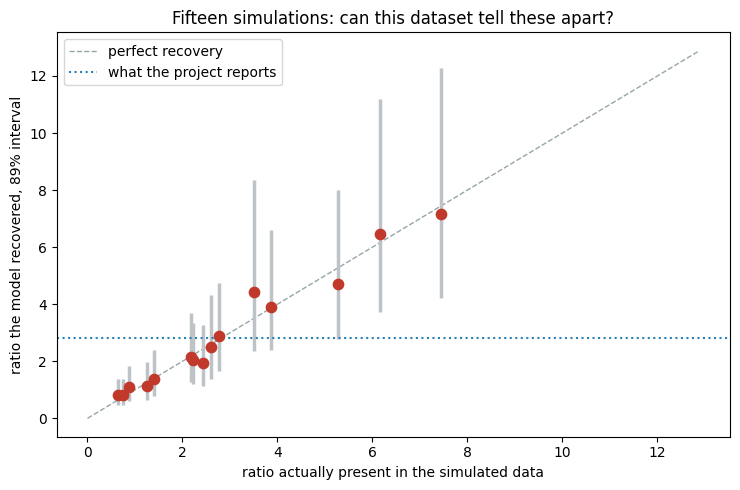

In [77]:
figure, ax = plt.subplots(figsize=(7.5, 5))
limit = recovery['upper_89'].max() * 1.05
ax.plot([0, limit], [0, limit], color='#95a5a6', ls='--', lw=1, label='perfect recovery')
ax.vlines(recovery['realised'], recovery['lower_89'], recovery['upper_89'],
          color='#bdc3c7', lw=2.5)
ax.scatter(recovery['realised'], recovery['recovered'], s=55, c='#c0392b', zorder=3)
ax.axhline(2.80, color='#2980b9', ls=':', lw=1.5, label='what the project reports')
ax.set_xlabel('ratio actually present in the simulated data')
ax.set_ylabel('ratio the model recovered, 89% interval')
ax.set_title('Fifteen simulations: can this dataset tell these apart?')
ax.legend()
plt.tight_layout()
plt.show()

### The headline is earned, and the bias I claimed does not exist

**The starting assumptions are not driving anything.** The ratio reads 2.804, 2.802, 2.809 and 2.822
across a threefold change in how large the model was told the pieces could be, including the matched
settings that remove the asymmetry entirely. A movement of 0.02, against this notebook's own range of
[1.53, 5.16] at 1,000 draws or the [1.57, 5.27] notebook 03 reports at 2,000, means the data decides
this and not the assumption.

**The range each fit reports is the right width, and if anything a little too wide.** Each fit reports
a range it is 89% confident about, so if the method is working, about 89 of every 100 such ranges
should contain the true answer. Across the simulations, **fifteen of fifteen** ranges contain the
ratio that was present, against 13.3 expected. The ranges are wide, and wide is right: a simulation
whose true ratio was 2.77 came back as [1.66, 4.74], close to the [1.53, 5.16] this notebook's refit
reports on the real data.

**There is no detectable bias in either direction.** Dividing what the model recovered by what was
actually there gives a median of **0.984** and a mean of **1.025**, with a standard error of 0.036 and
a 95% interval of [0.954, 1.095]. That one is a confidence interval on the mean across the fifteen
replicates, not a posterior interval, which is why it is 95% where everything else here is 89%. It
contains 1.0, so the method is not measurably biased high or low.

**Two earlier versions of this test were wrong, and both failures looked like findings at the time.**
The first scored against the setting the effects were requested at rather than the spread they
actually had, and reported a 30% upward bias. The second fixed that but set the random seed from the replicate number
alone, so `simulate()` drew identical driver, season and residual effects for every scenario and only
rescaled the car effects: three scenarios were one draw at three scales, and the apparent 11%
underestimate was a property of that one draw rather than of the method. Seeding on the (scenario,
replicate) pair gives 15 independent simulations, and it disappears.

**So the earlier conclusion that 2.8 is a floor because the method underestimates is withdrawn.** Q1
sandbagging still pushes the car share down, and that argument is untouched, but it now stands alone
rather than alongside a second mechanism that turned out to be a by-product of my own seeding.

**The data can tell the scenarios apart.** The five simulations built at a target ratio of 1 produced
actual ratios from 0.64 to 1.40, recovered 0.80 to 1.37, and the highest upper bound any of them
reported was **2.379**. The value observed on real F1 data, 2.804, sits above every one of them. **If
the driver mattered as much as the car, this dataset and this model would have said so.**

Note how far the actual ratio wanders from the one requested. Drawing 43 driver effects and 81 car
effects gave anything from 2.22 to 7.44 when the target was 5.0. That is why the scoring is against
what was drawn rather than what was asked for, and why three replicates could not have settled this.

### What this means for the reported number

The estimate needs no correction.

One directional caveat survives, and only one: **Q1 sandbagging**. A car quick enough to be certain of
getting through Q1 has no reason to show its full pace there, so the measured gap between the fastest
and slowest cars is smaller than the real one, which understates the car's share. Notebook 03
evidences it twice. So 2.8 is a floor because of sandbagging, not because of anything in how the
number is estimated.

The wider point is that the range matters more than the single figure. [1.57, 5.27] is what the data
supports; the simulations show that ranges of that width are correct rather than lazy; and notebook 06
spans 1.9x to 4.7x across different parts of qualifying and different data filters. Quote the range.